# **Analisis de Mejor alternativa de Producto** #

## Hecho por ##

Rene Zapata Hernandez

Camilo Andres Mendez Cogollo

Estid Esteban Vásquez


## Objetivo ##
Extraer, procesar y comparar información de audífonos disponibles en diferentes tiendas en línea, utilizando técnicas de web scraping y análisis de datos.

## El proyecto consulta información de: ##

Ktronix
Alkosto
Falabella
Los datos obtenidos permiten comparar precios, disponibilidad y características técnicas, con el propósito de identificar alternativas de compra y analizar su relación costo-beneficio.

## Librerias utilizadas ##
Python
Jupyter Notebook
Requests
BeautifulSoup
Pandas
Pytest
Git
GitHub
GitHub Actions

In [1]:
#IMPORTS PARA EL NOTEBOOK
import sys
from pathlib import Path

ruta_proyecto = Path.cwd().parent

if str(ruta_proyecto) not in sys.path:
    sys.path.append(str(ruta_proyecto))

import pandas as pd

from src.scraping import (
    extraer_datos_ktronix,
    extraer_datos_alkosto,
    extraer_datos_falabella
)

from src.procesamiento import (
    comparar_productos,
    normalizar_caracteristicas,
    calcular_costo_beneficio
)

from src.config import (
    URL_KTRONIX,
    URL_ALKOSTO,
    URL_FALABELLA
)

print("Módulos cargados correctamente.")

Módulos cargados correctamente.


# Extracción de la información #
A continuación se realiza la extracción de información directamente desde las tres tiendas seleccionadas.

In [2]:
producto_ktronix = extraer_datos_ktronix(
    URL_KTRONIX
)

producto_alkosto = extraer_datos_alkosto(
    URL_ALKOSTO
)

producto_falabella = extraer_datos_falabella(
    URL_FALABELLA
)

productos = [
    producto_ktronix,
    producto_alkosto,
    producto_falabella
]

print("Productos extraídos:", len(productos))

Productos extraídos: 3


In [3]:
# Mostrar los datos extraídos
datos_basicos = []

for producto in productos:

    datos_basicos.append({
        "Tienda": producto["tienda"],
        "Producto": producto["nombre"],
        "SKU": producto["sku"],
        "Precio": producto["precio_actual"],
        "Disponibilidad": producto["disponibilidad"]
    })


df_productos = pd.DataFrame(datos_basicos)

df_productos

,Tienda,Producto,SKU,Precio,Disponibilidad
0,Ktronix,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,195950543612,$999.010,Disponible
1,Alkosto,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,195950543612,$999.010,Disponible
2,Falabella,Audífonos AirPods 5 Carga Inalambrica,73730347,$679.900,Disponible


# 2. Comparación de precios
Los precios extraidos se normalizan con el script preparado en procesamiento de datos para definir su orden y comparativa

In [4]:
comparacion = comparar_productos(productos)

datos_comparacion = []

for producto in comparacion:

    datos_comparacion.append({
        "Tienda": producto["tienda"],
        "Producto": producto["nombre"],
        "Precio": producto["precio_numerico"]
    })


df_comparacion = pd.DataFrame(
    datos_comparacion
)

df_comparacion

,Tienda,Producto,Precio
0,Falabella,Audífonos AirPods 5 Carga Inalambrica,679900
1,Ktronix,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,999010
2,Alkosto,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,999010


In [5]:
# Producto con menor precio segun la comparativa

producto_menor_precio = comparacion[0]

print("Producto con menor precio")
print("--------------------------")

print(
    "Tienda:",
    producto_menor_precio["tienda"]
)

print(
    "Producto:",
    producto_menor_precio["nombre"]
)

print(
    "Precio:",
    f"${producto_menor_precio['precio_numerico']:,}"
)

Producto con menor precio
--------------------------
Tienda: Falabella
Producto: Audífonos AirPods 5 Carga Inalambrica
Precio: $679,900


# 3. Normalización de características #
Las tiendas pueden utilizar nombres diferentes para representar características equivalentes. Por esta razón, se normalizan los datos antes de realizar la comparación.

In [6]:
productos_normalizados = [
    normalizar_caracteristicas(producto)
    for producto in productos
]

df_caracteristicas = pd.DataFrame(productos_normalizados)

df_caracteristicas[
    [
        "tienda",
        "modelo",
        "precio",
        "conectividad",
        "autonomia",
        "cancelacion_ruido",
        "resistencia_agua"
    ]
]

,tienda,modelo,precio,conectividad,autonomia,cancelacion_ruido,resistencia_agua
0,Ktronix,AirPods Pro 3,999010,Bluetooth,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57)
1,Alkosto,AirPods Pro 3,999010,Bluetooth,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57)
2,Falabella,AirPods 5 Carga inalambrica,679900,Bluetooth,Hasta 22 horas de autonomía total combinada us...,No disponible,No disponible


# 4. Análisis costo-beneficio #
Para complementar la comparación por precio se utiliza un modelo de puntuación que considera precio y características técnicas del producto.

Las ponderaciones utilizadas son:

Precio: 40 %
Autonomía: 25 %
Cancelación de ruido: 20 %
Resistencia al agua: 15 %
El puntaje máximo posible es 100.

In [7]:
ranking = calcular_costo_beneficio(productos)

datos_ranking = []

for producto in ranking:

    datos_ranking.append({
        "Tienda": producto["tienda"],
        "Producto": producto["nombre"],
        "Precio": producto["precio"],
        "Autonomía": producto["autonomia"],
        "Cancelación de ruido": producto["cancelacion_ruido"],
        "Resistencia al agua": producto["resistencia_agua"],
        "Puntaje": producto["puntaje"]
    })

df_ranking = pd.DataFrame(datos_ranking)

df_ranking

,Tienda,Producto,Precio,Autonomía,Cancelación de ruido,Resistencia al agua,Puntaje
0,Ktronix,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,999010,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57),71.31
1,Alkosto,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,999010,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57),71.31
2,Falabella,Audífonos AirPods 5 Carga Inalambrica,679900,Hasta 22 horas de autonomía total combinada us...,No disponible,No disponible,65.00


In [8]:
# Con el resultado anterior sacamos el mejor costo-beneficio
mejor = ranking[0]

print("MEJOR RELACIÓN COSTO-BENEFICIO")
print("--------------------------------")

print("Tienda:", mejor["tienda"])
print("Producto:", mejor["nombre"])
print("Precio:", f"${mejor['precio']:,}")
print("Puntaje:", f"{mejor['puntaje']}/100")

MEJOR RELACIÓN COSTO-BENEFICIO
--------------------------------
Tienda: Ktronix
Producto: Audifonos APPLE AirPods Pro 3 Estuche MagSafe USB-C Blanco
Precio: $999,010
Puntaje: 71.31/100


## Graficos de comparativas

Text(0.5, 0, 'Tienda')

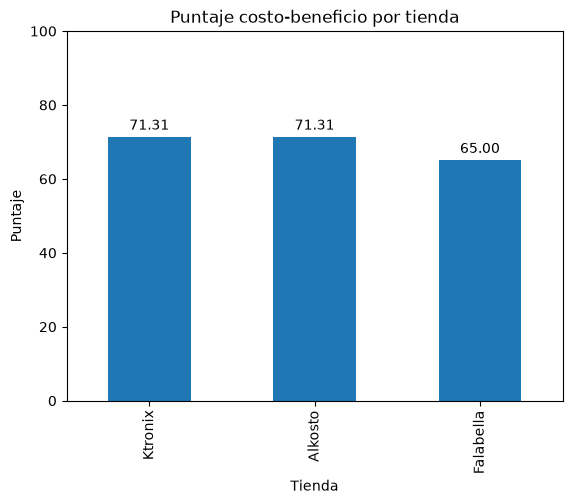

In [9]:
ax = df_ranking.plot(
    x="Tienda",
    y="Puntaje",
    kind="bar",
    legend=False,
    title="Puntaje costo-beneficio por tienda",
    ylim=(0, 100)
)

# Mostrar el puntaje encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.2f",
        padding=3
    )

ax.set_ylabel("Puntaje")
ax.set_xlabel("Tienda")

Text(0.5, 0, 'Tienda')

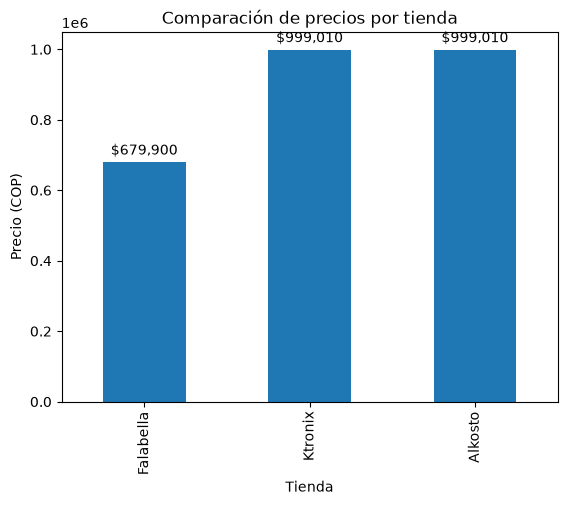

In [10]:
# Grafico de precios
ax = df_comparacion.plot(
    x="Tienda",
    y="Precio",
    kind="bar",
    legend=False,
    title="Comparación de precios por tienda"
)

# Mostrar precio encima de cada barra
for contenedor in ax.containers:
    etiquetas = [
        f"${valor:,.0f}"
        for valor in df_comparacion["Precio"]
    ]

    ax.bar_label(
        contenedor,
        labels=etiquetas,
        padding=3
    )

ax.set_ylabel("Precio (COP)")
ax.set_xlabel("Tienda")

# Exporte de Resultados #
Los productos extraídos, sus características normalizadas y el puntaje de costo-beneficio se consolidan en un DataFrame de Pandas.

Posteriormente, el DataFrame se exporta al archivo data/productos.csv, permitiendo utilizar los resultados en otras herramientas de análisis como Microsoft Excel o Power BI.

Cada nueva ejecución actualiza el archivo CSV con la información más reciente obtenida desde las tiendas en línea.

In [11]:
# Normalizar características de los productos
productos_normalizados = [
    normalizar_caracteristicas(producto)
    for producto in productos
]

# Calcular ranking costo-beneficio
ranking = calcular_costo_beneficio(productos)

# Relacionar cada producto con su puntaje
puntajes = {
    (producto["tienda"], producto["nombre"]): producto["puntaje"]
    for producto in ranking
}

datos_basicos = []

for producto, normalizado in zip(
    productos,
    productos_normalizados
):
    clave_producto = (
        producto["tienda"],
        producto["nombre"]
    )

    datos_basicos.append({
        "Tienda": producto["tienda"],
        "Producto": producto["nombre"],
        "SKU": producto["sku"],
        "Precio": producto["precio_actual"],
        "Precio_numérico": normalizado["precio"],
        "Disponibilidad": producto["disponibilidad"],
        "Modelo": normalizado["modelo"],
        "Conectividad": normalizado["conectividad"],
        "Autonomía": normalizado["autonomia"],
        "Cancelación_ruido": normalizado["cancelacion_ruido"],
        "Resistencia_agua": normalizado["resistencia_agua"],
        "Puntaje_costo_beneficio": puntajes.get(
            clave_producto,
            "No calculado"
        ),
        "URL": producto["url"]
    })

df_productos = pd.DataFrame(datos_basicos)

df_productos

,Tienda,Producto,SKU,Precio,Precio_numérico,Disponibilidad,Modelo,Conectividad,Autonomía,Cancelación_ruido,Resistencia_agua,Puntaje_costo_beneficio,URL
0,Ktronix,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,195950543612,$999.010,999010,Disponible,AirPods Pro 3,Bluetooth,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57),71.31,https://www.ktronix.com/audifonos-apple-airpod...
1,Alkosto,Audifonos APPLE AirPods Pro 3 Estuche MagSafe ...,195950543612,$999.010,999010,Disponible,AirPods Pro 3,Bluetooth,8 Horas Aproximadas,Sí,Resistencia al Agua (IP57),71.31,https://www.alkosto.com/audifonos-apple-airpod...
2,Falabella,Audífonos AirPods 5 Carga Inalambrica,73730347,$679.900,679900,Disponible,AirPods 5 Carga inalambrica,Bluetooth,Hasta 22 horas de autonomía total combinada us...,No disponible,No disponible,65.00,https://www.falabella.com.co/falabella-co/prod...


In [12]:
ruta_csv = ruta_proyecto / "data" / "productos.csv"

# Validar si el archivo ya existe
archivo_existe = ruta_csv.exists()

df_productos.to_csv(
    ruta_csv,
    mode="a",
    header=not archivo_existe,
    index=False,
    encoding="utf-8-sig"
)

print(f"Resultados agregados correctamente en: {ruta_csv}")

Resultados agregados correctamente en: c:\Pers\OneDrive\Documentos\Universidad\Ingenieria De Datos\Programación Para Analisis De Datos\ActividadFinalPOOII\AnalisisCompra\data\productos.csv


# Estructura del proyecto #
El proyecto está organizado de forma modular para separar la configuración, extracción, procesamiento, pruebas y análisis de los datos. Esto facilita el mantenimiento del código y permite modificar una parte del proyecto sin afectar innecesariamente las demás.

src/
Contiene la lógica principal de la aplicación.

config.py
Contiene las URL de los productos utilizados en el análisis para Ktronix, Alkosto y Falabella. Centralizar las URL permite cambiar los productos consultados sin tener que modificar los diferentes scripts del proyecto.

scraping.py
Contiene las funciones encargadas de conectarse a las tiendas en línea y extraer la información de los productos mediante requests y BeautifulSoup. Incluye funciones independientes para Ktronix, Alkosto y Falabella.

procesamiento.py
Contiene las funciones utilizadas para limpiar, transformar y analizar los datos obtenidos. Aquí se realiza la normalización de precios y características, la comparación de productos y el cálculo de la relación costo-beneficio.

__init__.py
Permite que la carpeta src sea utilizada como un paquete de Python y que sus módulos puedan importarse desde otros componentes del proyecto.

scripts/
Contiene scripts utilizados durante el desarrollo para ejecutar y validar individualmente los diferentes componentes.

ejecutar_scraping.py
Ejecuta y prueba la extracción de información desde Ktronix.

ejecutar_alkosto.py
Ejecuta y prueba el scraper correspondiente a Alkosto.

ejecutar_falabella.py
Ejecuta y prueba el scraper correspondiente a Falabella.

probar_comparacion.py
Permite validar de forma independiente la lógica utilizada para ordenar y comparar productos según su precio.

comparar_tiendas.py
Integra los tres scrapers y realiza una comparación automática de los precios obtenidos directamente desde las tiendas.

analizar_costo_beneficio.py
Integra los datos extraídos y ejecuta el modelo de evaluación costo-beneficio utilizando precio y características técnicas.

tests/
Contiene las pruebas automatizadas del proyecto.

test_procesamiento.py
Verifica mediante pytest que funciones como la limpieza de precios, comparación, normalización de características, procesamiento de autonomía y cálculo de costo-beneficio produzcan los resultados esperados.
Estas pruebas posteriormente son utilizadas por el pipeline de CI/CD para validar automáticamente los cambios realizados en el repositorio.

notebooks/
Contiene la capa de análisis y presentación del proyecto.

analisis_audifonos.ipynb
Notebook principal del proyecto. Integra los módulos de extracción y procesamiento para presentar tablas comparativas, análisis de precios, características, costo-beneficio, gráficos y conclusiones.
Archivos adicionales
requirements.txt
Define las librerías necesarias para ejecutar el proyecto, como requests, beautifulsoup4, pandas, pytest, jupyter e ipykernel.

README.md
Documenta el propósito del proyecto, requisitos, instalación, ejecución, estructura y flujo de trabajo.

## Flujo general de la solución ##
El funcionamiento general del proyecto sigue la siguiente secuencia:

Configuración de URLs → Web Scraping → Extracción de datos → Procesamiento y normalización → Comparación → Análisis costo-beneficio → Visualización en Jupyter Notebook 